In [15]:
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error
import pandas as pd
from sklearn.model_selection import train_test_split

In [16]:
insurence_data=pd.read_csv("insurance.csv")


X = insurence_data.drop(columns=["charges"])
y = insurence_data["charges"]

X=pd.get_dummies(X,columns=["region"],drop_first=False,dtype=int)

X["sex"] = X["sex"].map({"female": 1, "male": 0})
X["smoker"] = X["smoker"].map({"yes": 1, "no": 0})

X['age_smoker']=X['age']*X['smoker']
X['bmi_smoker']=X['bmi']*X['smoker']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42)

MSE for alpha={a}: 21929193.96542358
MSE for alpha={a}: 21929190.458955117
MSE for alpha={a}: 21929186.07625355
MSE for alpha={a}: 21929151.018425487
MSE for alpha={a}: 21929139.773926985
MSE for alpha={a}: 21929084.46320677
MSE for alpha={a}: 21928919.294083584
MSE for alpha={a}: 21928645.051149946
MSE for alpha={a}: 21928100.498498823
MSE for alpha={a}: 21927561.246888205
MSE for alpha={a}: 21926498.47434043
MSE for alpha={a}: 21925456.632986896
MSE for alpha={a}: 21923933.425055552
MSE for alpha={a}: 21919198.03845221
MSE for alpha={a}: 21914988.277346365
MSE for alpha={a}: 21911304.10550219
MSE for alpha={a}: 21908145.96453166
MSE for alpha={a}: 21903405.366266567
MSE for alpha={a}: 21900233.721034084
MSE for alpha={a}: 21905453.685933713
MSE for alpha={a}: 21923800.210334063
MSE for alpha={a}: 21955271.226277314
MSE for alpha={a}: 21999865.695277996
MSE for alpha={a}: 22128424.95431352
MSE for alpha={a}: 22292646.382132042
MSE for alpha={a}: 22880351.88380496
MSE for alpha={a}: 23

<Axes: >

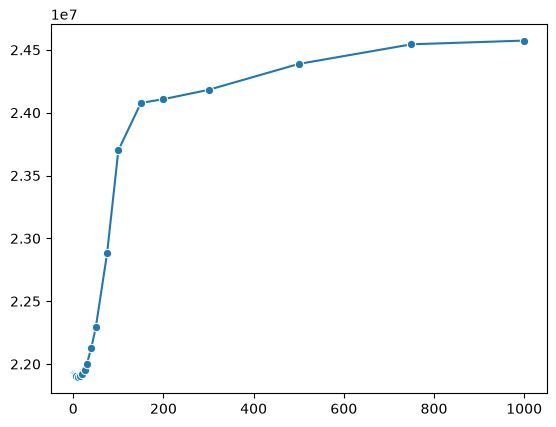

In [ ]:
import seaborn as sns
alphas = [
    0.0001, 0.0005, 0.001, 0.005,
    0.01, 0.02, 0.05, 0.1, 0.2, 0.3,
    0.5, 0.7, 1, 2, 3, 4, 5, 7, 10,
    15, 20, 25, 30, 40, 50, 75, 100,
    150, 200, 300, 500, 750, 1000
]
mess=[]
for a in alphas:
    lasso_model = Lasso(alpha=a)
    lasso_model.fit(X_train, y_train)

    y_pred = lasso_model.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    print("MSE for alpha={a}:", mse)
    mess.append(mse)

sns.lineplot(x=alphas,y=mess,marker="o")
